<a href="https://colab.research.google.com/github/FatherNurt/FPDP-Engine/blob/MAIN/Physmatics_Laws_%26_Invariants_Compendium_(v1_0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Core Operator Reference ===

Core operator functions defined.

=== Transport Invariant Reference ===

Transport Invariant demo complete.
Final X value after 100 steps: 7.035

=== ψ Coordinate Hygiene Demo ===

ψ under proper log coordinate:
  Mean ψ   = 1.9606
  Std ψ    = 2.7929
  Median ψ = 2.2485

=== Fractaile Scaling Reference ===

Fractaile scaling (D ≈ 1.20):
  N =     10  →  Scaled = 15.85
  N =    100  →  Scaled = 251.19
  N =   1000  →  Scaled = 3981.07
  N =  10000  →  Scaled = 63095.73

Note: Effective dimension typically stabilizes in 1.18 ≤ D ≤ 1.22 range.



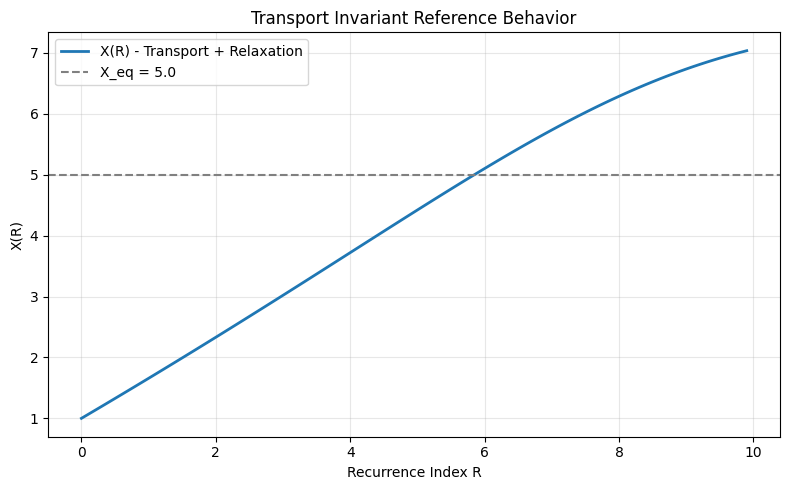


C3 QUICK REFERENCE TABLE

Core Operators:
  • Log–Ψ     : Recurrence gradient (ψ = dS/dR)
  • 2√        : Constrained transport within regime
  • hHRT      : Relaxation toward equilibrium
  • h³π       : Regime transition / re-indexing marker

Key Invariants:
  • Transport Invariant (primary dynamical invariant)
  • Recurrence Gradient Invariance (under admissible coordinates)
  • Fractaile Geometric Invariance (D ≈ 1.18–1.22)
  • Phase & Resonance regularities (60° phase law, Rₘ)

Geometric / Structural:
  • Fractaile geometry
  • Hydrogen Torus Geometry (S-functional)
  • Heisenberg Geometric Floor
  • HRB / HTB band architecture

Coordinate Hygiene (required for invariance claims):
  • Positive + dimensionless + ratio-scale (canonically logarithmic)

Reframed Constants:
  • Planck units, k_B, e, Nₐ → treated as resonance quantities
    (see C3 Section 7 for details)


Notebook execution complete.


In [1]:
# =========================================================
# Physmatics Laws & Invariants Compendium (v1.0)
# Companion Notebook (Lightweight Reference Version)
# Matching C3 Document
# =========================================================

"""
This notebook provides practical reference implementations and
demonstrations for the core concepts in the
Physmatics Laws & Invariants Compendium (C3).

It is intentionally kept lightweight for quick reference and exploration.
"""

# =========================================================
# 1. Core Operators - Reference Implementations
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

print("=== Core Operator Reference ===\n")

# --- 2√ Constrained Transport (simplified modulator) ---
def f_2sqrt(R, R_t=10.0, p=4.0):
    """2√ transport constraint function"""
    return (R_t ** p) / (R ** p + R_t ** p)

# --- hHRT Relaxation ---
def hHRT_relaxation(X, X_eq, tau, dR=0.1):
    """Simple relaxation step toward equilibrium"""
    return X + dR * (- (X - X_eq) / tau)

# --- Log–Ψ (Recurrence Gradient) ---
def psi_log(S_values, R_values):
    """Calculate ψ under logarithmic recurrence coordinate"""
    log_R = np.log(R_values)
    dS = np.diff(S_values)
    dlogR = np.diff(log_R)
    return dS / dlogR

print("Core operator functions defined.\n")

# =========================================================
# 2. Transport Invariant - Lightweight Reference
# =========================================================

print("=== Transport Invariant Reference ===\n")

def transport_invariant_step(X, R, alpha=0.15, tau=8.0, X_eq=5.0, R_t=10.0, p=4.0, dR=0.1):
    """Single step of the coupled Transport Invariant"""
    transport = alpha * X * f_2sqrt(R, R_t, p)
    relaxation = (X - X_eq) / tau
    return X + dR * (transport - relaxation)

# Quick demonstration run
steps = 100
R_vals = np.zeros(steps)
X_vals = np.zeros(steps)
X_vals[0] = 1.0
R_vals[0] = 0.0

for i in range(1, steps):
    R_vals[i] = R_vals[i-1] + 0.1
    X_vals[i] = transport_invariant_step(X_vals[i-1], R_vals[i])

print(f"Transport Invariant demo complete.")
print(f"Final X value after {steps} steps: {X_vals[-1]:.3f}\n")

# =========================================================
# 3. ψ Coordinate Hygiene Demonstration
# =========================================================

print("=== ψ Coordinate Hygiene Demo ===\n")

# Create simple increasing functional S under recurrence R
R = np.linspace(1, 100, 50)
S = np.log(R) * 2 + np.random.normal(0, 0.1, len(R))   # example functional

# Under proper log coordinate (admissible)
psi_proper = psi_log(S, R)

print(f"ψ under proper log coordinate:")
print(f"  Mean ψ   = {np.mean(psi_proper):.4f}")
print(f"  Std ψ    = {np.std(psi_proper):.4f}")
print(f"  Median ψ = {np.median(psi_proper):.4f}\n")

# =========================================================
# 4. Simple Fractaile Scaling Example
# =========================================================

print("=== Fractaile Scaling Reference ===\n")

def fractaile_scaling(N, D=1.20):
    """Simple recursive scaling with effective dimension D"""
    return N ** D

N_values = np.array([10, 100, 1000, 10000])
scaled = fractaile_scaling(N_values, D=1.20)

print("Fractaile scaling (D ≈ 1.20):")
for n, s in zip(N_values, scaled):
    print(f"  N = {n:6d}  →  Scaled = {s:.2f}")

print("\nNote: Effective dimension typically stabilizes in 1.18 ≤ D ≤ 1.22 range.\n")

# =========================================================
# 5. Quick Visualization - Transport Invariant Behavior
# =========================================================

plt.figure(figsize=(8, 5))
plt.plot(R_vals, X_vals, linewidth=2, label='X(R) - Transport + Relaxation')
plt.axhline(y=5.0, color='gray', linestyle='--', label='X_eq = 5.0')
plt.xlabel('Recurrence Index R')
plt.ylabel('X(R)')
plt.title('Transport Invariant Reference Behavior')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 6. Summary Reference Table (Text)
# =========================================================

print("""
=============================================================
C3 QUICK REFERENCE TABLE
=============================================================

Core Operators:
  • Log–Ψ     : Recurrence gradient (ψ = dS/dR)
  • 2√        : Constrained transport within regime
  • hHRT      : Relaxation toward equilibrium
  • h³π       : Regime transition / re-indexing marker

Key Invariants:
  • Transport Invariant (primary dynamical invariant)
  • Recurrence Gradient Invariance (under admissible coordinates)
  • Fractaile Geometric Invariance (D ≈ 1.18–1.22)
  • Phase & Resonance regularities (60° phase law, Rₘ)

Geometric / Structural:
  • Fractaile geometry
  • Hydrogen Torus Geometry (S-functional)
  • Heisenberg Geometric Floor
  • HRB / HTB band architecture

Coordinate Hygiene (required for invariance claims):
  • Positive + dimensionless + ratio-scale (canonically logarithmic)

Reframed Constants:
  • Planck units, k_B, e, Nₐ → treated as resonance quantities
    (see C3 Section 7 for details)

=============================================================
""")

print("Notebook execution complete.")
